#Transfer Learning for Computer Vision (Tutorial and Exercices)


This is a modified version of PyTorch tutorial:
https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

* License: BSD
* Author of original tutorial: Sasank Chilamkurthy https://chsasank.github.io
* Adapated and extended for teaching purpose by [Bruno Galerne](https://www.idpoisson.fr/galerne)


## Check that the colab has a GPU:
(otherwise go to Eit->Notebook properties ->...)

In [1]:
!nvidia-smi

Fri Feb  6 21:34:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
%matplotlib inline


Transfer Learning for Computer Vision Tutorial
==============================================
**Author**: `Sasank Chilamkurthy <https://chsasank.github.io>`_

In this tutorial, you will learn how to train a convolutional neural network for
image classification using transfer learning. You can read more about the transfer
learning at [cs231n notes](https://cs231n.github.io/transfer-learning/)

Quoting these notes,

    In practice, very few people train an entire Convolutional Network
    from scratch (with random initialization), because it is relatively
    rare to have a dataset of sufficient size. Instead, it is common to
    pretrain a ConvNet on a very large dataset (e.g. ImageNet, which
    contains 1.2 million images with 1000 categories), and then use the
    ConvNet either as an initialization or a fixed feature extractor for
    the task of interest.

These two major transfer learning scenarios look as follows:

-  **Finetuning the convnet**: Instead of random initializaion, we
   initialize the network with a pretrained network, like the one that is
   trained on imagenet 1000 dataset. Rest of the training looks as
   usual.
-  **ConvNet as fixed feature extractor**: Here, we will freeze the weights
   for all of the network except that of the final fully connected
   layer. This last fully connected layer is replaced with a new one
   with random weights and only this layer is trained.




In [3]:
# License: BSD
# Author: Sasank Chilamkurthy

from __future__ import print_function, division

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
import copy

plt.ion()   # interactive mode

Load Data
---------

We will use torchvision and torch.utils.data packages for loading the
data.

The problem we're going to solve today is to train a model to classify
**ants** and **bees**. We have about 120 training images each for ants and bees.
There are 75 validation images for each class. Usually, this is a very
small dataset to generalize upon, if trained from scratch. Since we
are using transfer learning, we should be able to generalize reasonably
well.

This dataset is a very small subset of imagenet.

.. Note ::
   Download the data from
   `here <https://download.pytorch.org/tutorial/hymenoptera_data.zip>`_
   and extract it to the current directory.



In [4]:
!wget 'https://download.pytorch.org/tutorial/hymenoptera_data.zip'
!unzip -nq hymenoptera_data.zip
!ls
!ls hymenoptera_data
!ls hymenoptera_data/train/


--2026-02-06 21:34:43--  https://download.pytorch.org/tutorial/hymenoptera_data.zip
Resolving download.pytorch.org (download.pytorch.org)... 18.239.83.32, 18.239.83.126, 18.239.83.16, ...
Connecting to download.pytorch.org (download.pytorch.org)|18.239.83.32|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 47286322 (45M) [application/zip]
Saving to: ‘hymenoptera_data.zip’

hymenoptera_data.zi 100%[===================>]  45.10M   134MB/s    in 0.3s    

2026-02-06 21:34:44 (134 MB/s) - ‘hymenoptera_data.zip’ saved [47286322/47286322]

hymenoptera_data  hymenoptera_data.zip	sample_data
train  val
ants  bees


In [5]:
# Data augmentation and normalization for training
# Just normalization for validation
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

data_dir = 'hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                             shuffle=True, num_workers=2)
              for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes
print('Class names are: ', class_names)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

Class names are:  ['ants', 'bees']


## Visualize a few images

Let's visualize a few training images so as to understand the data
augmentations.



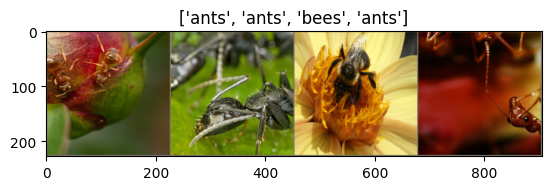

In [6]:
def imshow(inp, title=None):
    """Imshow for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated


# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

Training the model
------------------

Now, let's write a general function to train a model. Here, we will
illustrate:

-  Scheduling the learning rate
-  Saving the best model

In the following, parameter ``scheduler`` is an LR scheduler object from
``torch.optim.lr_scheduler``.



In [7]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data.
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                # zero the parameter gradients
                optimizer.zero_grad()

                # forward
                # track history if only in train
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # backward + optimize only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print('{} Loss: {:.4f} Acc: {:.4f}'.format(
                phase, epoch_loss, epoch_acc))

            # deep copy the model
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(
        time_elapsed // 60, time_elapsed % 60))
    print('Best val Acc: {:4f}'.format(best_acc))

    # load best model weights
    model.load_state_dict(best_model_wts)
    return model

## Visualizing the model predictions

Generic function to display predictions for a few images




In [8]:
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title('predicted: {}'.format(class_names[preds[j]]))
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

# Finetuning the pretrained convnet

Load a pretrained model and reset final fully connected layer.

Here we use **ResNet18**.

The original architecture of which is designed for the classification of 1000 ImageNet classes. The architecture is a 18-layer version of the one above (from the original paper: https://arxiv.org/pdf/1512.03385.pdf[texte du lien](https:// [texte du lien](https:// [texte du lien](https://))))



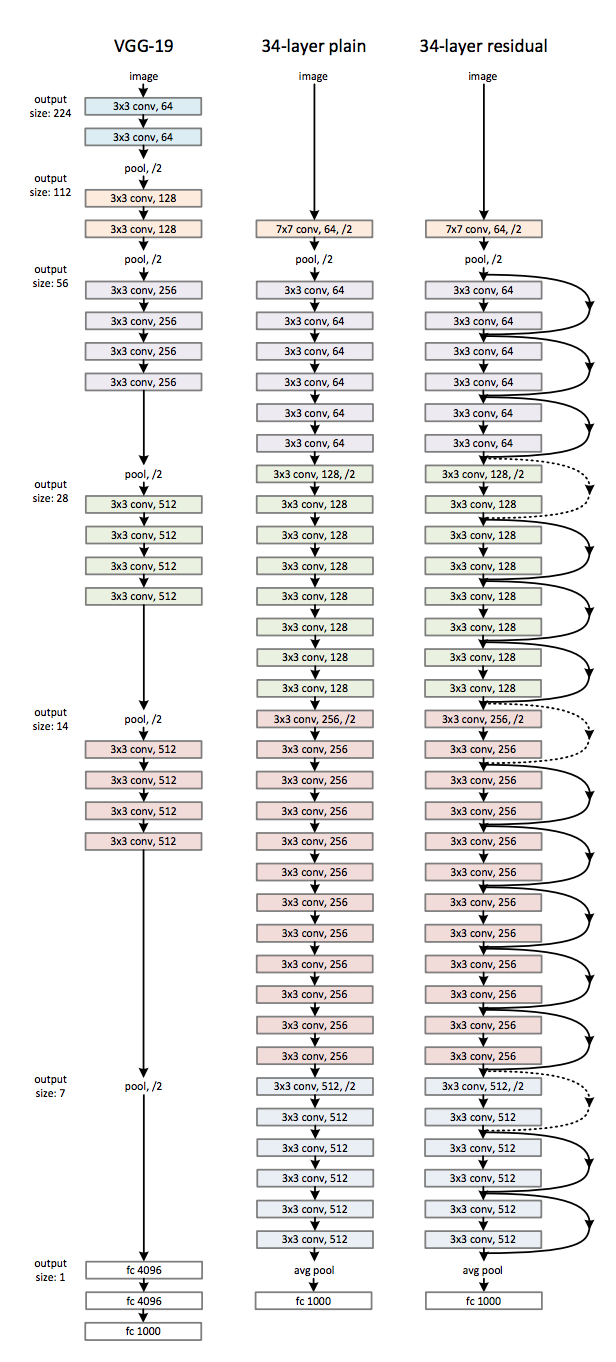





In short after a sequence of convolution layers and residual connections, the classification is done by a single fully connected layer after average pooling of spatial features.

Let's have a look at the model.
A first way is to use the print function of PyTorch:

In [9]:
model_ft = models.resnet18(pretrained=True)
print(model_ft)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 209MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

Another way to look at a model is to use the torchsummary lib that reproduces a keras functionnality:

In [10]:
import torchsummary
torchsummary.summary(model_ft.to(device), input_size=(3,224,224))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 112]           9,408
       BatchNorm2d-2         [-1, 64, 112, 112]             128
              ReLU-3         [-1, 64, 112, 112]               0
         MaxPool2d-4           [-1, 64, 56, 56]               0
            Conv2d-5           [-1, 64, 56, 56]          36,864
       BatchNorm2d-6           [-1, 64, 56, 56]             128
              ReLU-7           [-1, 64, 56, 56]               0
            Conv2d-8           [-1, 64, 56, 56]          36,864
       BatchNorm2d-9           [-1, 64, 56, 56]             128
             ReLU-10           [-1, 64, 56, 56]               0
       BasicBlock-11           [-1, 64, 56, 56]               0
           Conv2d-12           [-1, 64, 56, 56]          36,864
      BatchNorm2d-13           [-1, 64, 56, 56]             128
             ReLU-14           [-1, 64,

What is important for classification is the last layer:
>   (fc): Linear(in_features=512, out_features=1000, bias=True)


resnet18 extracts 512 features from images, then uses a linear layer with 1000 outputs for a classification (with crossentropy loss that includes the softmax layer).


### Adapting the model to our task:

We need to adapt the network to our classification with only 2 classes (bees and ants).

In [11]:
num_ftrs = model_ft.fc.in_features
# Here the size of each output sample is set to 2.
# Alternatively, it can be generalized to nn.Linear(num_ftrs, len(class_names)).
model_ft.fc = nn.Linear(num_ftrs, 2)

model_ft = model_ft.to(device)
print(model_ft.fc)

criterion = nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

Linear(in_features=512, out_features=2, bias=True)


## Train and evaluate

It should take around 15-25 min on CPU. On GPU though, it takes less than 2
minutes.




In [12]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler,
                       num_epochs=25)

Epoch 0/24
----------
train Loss: 0.5416 Acc: 0.7131
val Loss: 0.2875 Acc: 0.9020

Epoch 1/24
----------
train Loss: 0.5035 Acc: 0.7705
val Loss: 0.4495 Acc: 0.8039

Epoch 2/24
----------
train Loss: 0.5370 Acc: 0.7869
val Loss: 0.3292 Acc: 0.8693

Epoch 3/24
----------
train Loss: 0.6033 Acc: 0.8074
val Loss: 0.4242 Acc: 0.8693

Epoch 4/24
----------
train Loss: 0.4495 Acc: 0.8566
val Loss: 0.2866 Acc: 0.9020

Epoch 5/24
----------
train Loss: 0.6210 Acc: 0.7541
val Loss: 0.2240 Acc: 0.9281

Epoch 6/24
----------
train Loss: 0.4939 Acc: 0.7992
val Loss: 0.3164 Acc: 0.8824

Epoch 7/24
----------
train Loss: 0.4745 Acc: 0.7951
val Loss: 0.2496 Acc: 0.9281

Epoch 8/24
----------
train Loss: 0.2082 Acc: 0.9303
val Loss: 0.2526 Acc: 0.9216

Epoch 9/24
----------
train Loss: 0.2552 Acc: 0.8934
val Loss: 0.2301 Acc: 0.9346

Epoch 10/24
----------
train Loss: 0.3226 Acc: 0.8361
val Loss: 0.2214 Acc: 0.9346

Epoch 11/24
----------
train Loss: 0.2310 Acc: 0.9262
val Loss: 0.2411 Acc: 0.9346

Ep

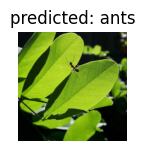

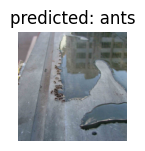

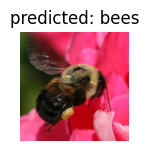

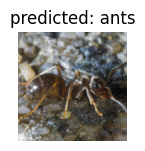

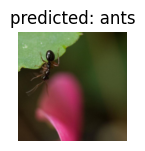

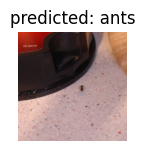

In [13]:
visualize_model(model_ft)

# Pretrained ConvNet as fixed feature extractor

Here, we need to freeze all the network except the final layer. We need
to set ``requires_grad == False`` to freeze the parameters so that the
gradients are not computed in ``backward()``.

You can read more about this in the documentation
`here <https://pytorch.org/docs/notes/autograd.html#excluding-subgraphs-from-backward>`__.




In [14]:
model_conv = torchvision.models.resnet18(pretrained=True)
for param in model_conv.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that only parameters of final layer are being optimized as
# opposed to before.
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

## Train and evaluate

On CPU this will take about half the time compared to previous scenario.
This is expected as gradients don't need to be computed for most of the
network. However, forward does need to be computed.




In [15]:
model_conv = train_model(model_conv, criterion, optimizer_conv,
                         exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------
train Loss: 0.6582 Acc: 0.6516
val Loss: 0.2723 Acc: 0.8889

Epoch 1/24
----------
train Loss: 0.5926 Acc: 0.6967
val Loss: 0.1752 Acc: 0.9608

Epoch 2/24
----------
train Loss: 0.4218 Acc: 0.7869
val Loss: 0.2231 Acc: 0.9150

Epoch 3/24
----------
train Loss: 0.5180 Acc: 0.7623
val Loss: 0.2126 Acc: 0.9150

Epoch 4/24
----------
train Loss: 0.5016 Acc: 0.7992
val Loss: 0.1864 Acc: 0.9346

Epoch 5/24
----------
train Loss: 0.4863 Acc: 0.8033
val Loss: 0.1635 Acc: 0.9542

Epoch 6/24
----------
train Loss: 0.3689 Acc: 0.8279
val Loss: 0.1952 Acc: 0.9412

Epoch 7/24
----------
train Loss: 0.3993 Acc: 0.8443
val Loss: 0.2009 Acc: 0.9281

Epoch 8/24
----------
train Loss: 0.3420 Acc: 0.8443
val Loss: 0.1699 Acc: 0.9477

Epoch 9/24
----------
train Loss: 0.3210 Acc: 0.8648
val Loss: 0.1858 Acc: 0.9477

Epoch 10/24
----------
train Loss: 0.4045 Acc: 0.8115
val Loss: 0.1958 Acc: 0.9412

Epoch 11/24
----------
train Loss: 0.2598 Acc: 0.9016
val Loss: 0.1946 Acc: 0.9281

Ep

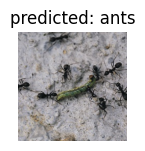

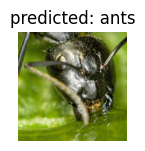

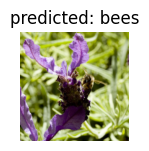

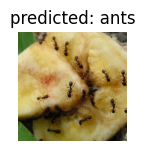

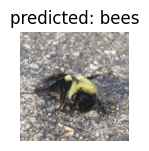

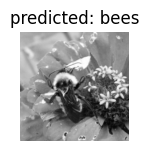

In [16]:
visualize_model(model_conv)

#Exercise 1: Discussion

1. Explain how the model given by the ```train_model``` function is selected.
2. What is missing here to assess the performance of this model (output of train function)?

## Exo1: Mes propositions
1. Pour chaque epoch, le modèle bascule entre "train" et "val". lorsqu'il est en mode train, il calcule la loss et mets à jour ses parametres. Lorsqu'il est en mode val, il regarde si l'accuracy actuelle est supérieur à la meilleur qu'il avait enregistré(c'est ça qui est écrit ici:

```
 if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

```

  )
; si oui, il utilise le modèle en cours pour travailler, sinon il utilise le modèle qui a la best accuracy.


2. On pourrait penser à faire une matrice de confusion pour comparer les résultats obtenu par le modèle et les vraies catégories. Celà permettrait de savoir à combien de pourcent le modèle se trompe ou pas.
Et aussi, utiliser le modèle sur des données qu'il n'a pas encore vu

#Exercise 2: Apply the same approach to VGG-19

In this exercice we will use the pretrained VGG19 model as a fixed feature extractor. However the classifier part of VGG19 is more complex than the one of Resnet18.


1. Adapt and retrain the last linear layer of the classifier part of the VGG19 model (see above cell).
2. Adapt the last layer and retrain all the parameters of the VGG19 model (fine tuning of all parameters).
3. Compare the results of both approaches.


In [17]:
model_conv = torchvision.models.vgg19(pretrained=True)
print("Full model")
print(model_conv)

print("\nClassifier part")
print(model_conv.classifier)
print("\nLast layer")
print(model_conv.classifier[6])


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:06<00:00, 91.1MB/s]


Full model
VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(

### Commentaire

Ici, le modèle a plusieurs couches. Celle qui nous interesse est la dernière. Elle se trouve dans la Classifier part et c'est la dernière. Affichons la.

In [18]:
print(model_conv.classifier[6])

Linear(in_features=4096, out_features=1000, bias=True)


### 1. adapter et ré entrainer la dernière couche linéaire du classifier

L'idée ici est de garder les paramètres du modèle mais, modifier la dernière couche pour faire ce qui nous intresse: faire 2 classes et aussi réajuster seulement les paramètres de la dernière couche.

In [19]:
model_conv = torchvision.models.vgg19(pretrained=True)
for param in model_conv.parameters():
    param.requires_grad = False


In [20]:
num_ftrs = model_conv.classifier[6].in_features
# on récupère le nbre de features qui doit rentrer dans la dernière couche

model_conv.classifier[6] = nn.Linear(num_ftrs, 2)
# on remplace par une couche linéaire qui sort 2 classes



In [21]:
print(num_ftrs)
#juste pour voir.
#le classifier[6] prend 4096 features en entrée

4096


In [22]:

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that only parameters of final layer are being optimized as

#on optimise que le dernier layer
optimizer_conv = optim.SGD(model_conv.classifier[6].parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

In [23]:
model_conv = train_model(model_conv, criterion, optimizer_conv,
                         exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------
train Loss: 0.2249 Acc: 0.8975
val Loss: 0.0911 Acc: 0.9673

Epoch 1/24
----------
train Loss: 0.1533 Acc: 0.9385
val Loss: 0.1209 Acc: 0.9673

Epoch 2/24
----------
train Loss: 0.1026 Acc: 0.9590
val Loss: 0.1455 Acc: 0.9673

Epoch 3/24
----------
train Loss: 0.1658 Acc: 0.9385
val Loss: 0.1392 Acc: 0.9673

Epoch 4/24
----------
train Loss: 0.1115 Acc: 0.9508
val Loss: 0.1514 Acc: 0.9608

Epoch 5/24
----------
train Loss: 0.1121 Acc: 0.9467
val Loss: 0.1073 Acc: 0.9608

Epoch 6/24
----------
train Loss: 0.1218 Acc: 0.9385
val Loss: 0.1148 Acc: 0.9673

Epoch 7/24
----------
train Loss: 0.1000 Acc: 0.9631
val Loss: 0.1124 Acc: 0.9608

Epoch 8/24
----------
train Loss: 0.0941 Acc: 0.9713
val Loss: 0.1164 Acc: 0.9804

Epoch 9/24
----------
train Loss: 0.0965 Acc: 0.9672
val Loss: 0.1164 Acc: 0.9739

Epoch 10/24
----------
train Loss: 0.1125 Acc: 0.9467
val Loss: 0.1111 Acc: 0.9739

Epoch 11/24
----------
train Loss: 0.1066 Acc: 0.9549
val Loss: 0.1127 Acc: 0.9739

Ep

### Mon commentaire

Ici, on voit que l'accuracy la meilleure accuracy qui est 0.9803. a été atteint pour l'epoch 8; pour le reste des epoch,  ce n'était plus aussi haut: c'était autour de 0.9673.
Il a fini en 1min44s

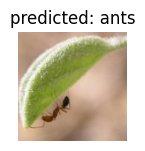

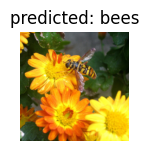

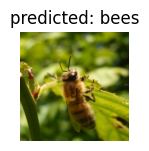

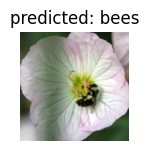

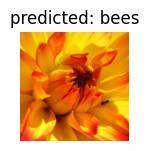

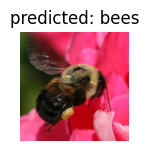

In [24]:
visualize_model(model_conv)

### Mon commentaire

Le modèle semble avoir assez bien prédit les classes.
Pour l'avant dernière et celle d'avant, je n'arrive pas à savoir si c'est "ants" ou "bees". Comme dans les deux, les insectes se trouvent dans des pétales, il est raisonnable de penser que ce sont des "bees" même si les insectes ne sont pas vraiment visible.

### 2. Faire du fine tuning

In [25]:
model_conv = torchvision.models.vgg19(pretrained=True)
print("Full model")
print(model_conv)

print("\nClassifier part")
print(model_conv.classifier)
print("\nLast layer")
print(model_conv.classifier[6])

Full model
VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(

### Commentaire

Comme avant, la dernière couche est capitale. Sauf que ici, au lieu de ne réajuster que les parametres de la dernière couche, on reajuste les poids de tt le model.

In [26]:
num_ftrs = model_conv.classifier[6].in_features
# Here the size of each output sample is set to 2.
# Alternatively, it can be generalized to nn.Linear(num_ftrs, len(class_names)).
model_conv.classifier[6] = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)
print(model_conv.classifier[6])

criterion = nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer_ft = optim.SGD(model_conv.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

Linear(in_features=4096, out_features=2, bias=True)


In [27]:
model_conv = train_model(model_conv, criterion, optimizer_ft, exp_lr_scheduler,
                       num_epochs=25)

Epoch 0/24
----------
train Loss: 0.6211 Acc: 0.7131
val Loss: 0.7057 Acc: 0.4771

Epoch 1/24
----------
train Loss: 0.7292 Acc: 0.4918
val Loss: 0.7488 Acc: 0.4575

Epoch 2/24
----------
train Loss: 0.7312 Acc: 0.4795
val Loss: 0.6903 Acc: 0.5425

Epoch 3/24
----------
train Loss: 0.7116 Acc: 0.4549
val Loss: 0.6600 Acc: 0.6536

Epoch 4/24
----------
train Loss: 0.6720 Acc: 0.6148
val Loss: 0.5990 Acc: 0.7712

Epoch 5/24
----------
train Loss: 0.6105 Acc: 0.6516
val Loss: 0.4742 Acc: 0.7778

Epoch 6/24
----------
train Loss: 0.6824 Acc: 0.5656
val Loss: 0.5931 Acc: 0.7255

Epoch 7/24
----------
train Loss: 0.5552 Acc: 0.7664
val Loss: 0.5168 Acc: 0.7974

Epoch 8/24
----------
train Loss: 0.4762 Acc: 0.8033
val Loss: 0.4393 Acc: 0.8235

Epoch 9/24
----------
train Loss: 0.4153 Acc: 0.8279
val Loss: 0.3748 Acc: 0.8497

Epoch 10/24
----------
train Loss: 0.3603 Acc: 0.8443
val Loss: 0.3377 Acc: 0.8693

Epoch 11/24
----------
train Loss: 0.3054 Acc: 0.8648
val Loss: 0.2701 Acc: 0.9020

Ep

### Mon commentaire

La meilleure accuracy a été atteint pour l'epoch 19. Après, pour les autres epoch, l'accuracy n'était plus aussi haut.
Il a fini en 3min39s

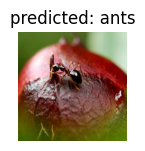

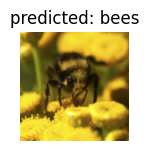

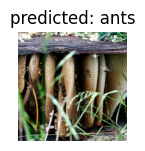

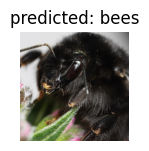

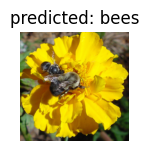

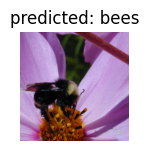

In [28]:
visualize_model(model_conv)

### Mon commentaire
Le modèle semble avoir bien prédit les classes. Cependant, sur certaines images, je n'arrive pas à distinguer la classe. Dans ces cas, il est interessant de se baser sur l'environnement pour essayer de distinguer la classe.

### 3. **Comparaison des 2 approches**

Dans notre cas, l'accuracy des  deux approches semblent être du même ordre de grandeur. Mais, la best accuracy de feature extraction (méthode de la question 1) est meilleure que la best accuracy de fine tuning.
De plus, la méthode feature extraction est plus rapide que la la méthode fine tuning dans notre cas.
Cela peut peut-être s'expliquer par le fait que le fine tuning réajuste tous les paramètres du modèle.

#Exercice 3: Classification of another dataset

In this exercise you will classify pictures of flowers.
First we describe the dataset and provide functions for loading the dataset in compatible form for PyTorch.

The exercise really begins once the dataloaders are defined.


### A little perspective:
Quoting the research work related to the database:

> *Automated Flower Classification over a Large Number of Classes*,
M. Nilsback, A. Zisserman,
Indian Conference on Computer Vision, Graphics and Image Processing, Dec 2008

https://www.robots.ox.ac.uk/~vgg/publications/2008/Nilsback08/

> Finally, using the features computed in this paper and the multiple kernel classifier leads to a performance of 88.33±0.3%. This is the best performance todate reported on the 17 class flower dataset.

You should get a better performance using off-the-shelf deep neural networks for image classification.
This shows once again the performance gain that deep neural networks allow for.


## 17 Category Flower Dataset
Dataset description:

 * Source: https://www.robots.ox.ac.uk/~vgg/data/flowers/17/index.html
 * 17 classes, 80 images per classes (total: 17*80 = 1360 images)
 * Images 1 to 80 are class 0, 81 to 160 are class 1 etc...
 * Classes in the image file order are

        classes = ['Daffodil','Snowdrop', 'Lily_Valley', 'Bluebell',
           'Crocus', 'Iris', 'Tigerlily', 'Tulip',
           'Fritillary', 'Sunflower', 'Daisy', 'Colts_Foot',
            'Dandelalion', 'Cowslip', 'Buttercup', 'Windflower',
            'Pansy']
 * 3 different train / val / test data splits are given by the authors in ```datasplits.mat```.

In [29]:
# get data:
!wget -c https://www.robots.ox.ac.uk/~vgg/data/flowers/17/17flowers.tgz
!wget -c https://www.robots.ox.ac.uk/~vgg/data/flowers/17/datasplits.mat
!tar zxf 17flowers.tgz
!ls
# should have a jpg/ folder

--2026-02-06 21:59:32--  https://www.robots.ox.ac.uk/~vgg/data/flowers/17/17flowers.tgz
Resolving www.robots.ox.ac.uk (www.robots.ox.ac.uk)... 129.67.94.2
Connecting to www.robots.ox.ac.uk (www.robots.ox.ac.uk)|129.67.94.2|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://thor.robots.ox.ac.uk/flowers/17/17flowers.tgz [following]
--2026-02-06 21:59:33--  https://thor.robots.ox.ac.uk/flowers/17/17flowers.tgz
Resolving thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)... 129.67.95.98
Connecting to thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)|129.67.95.98|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 60270631 (57M) [application/octet-stream]
Saving to: ‘17flowers.tgz’

17flowers.tgz       100%[===================>]  57.48M   190MB/s    in 0.3s    

2026-02-06 21:59:33 (190 MB/s) - ‘17flowers.tgz’ saved [60270631/60270631]

--2026-02-06 21:59:33--  https://www.robots.ox.ac.uk/~vgg/data/flowers/17/datasplits.mat
Resolving 

In [30]:
import scipy.io
ds = scipy.io.loadmat('datasplits.mat')
print(ds.keys())
#print(ds['trn1'])
print('total images for split 1: ', ds['trn1'].size + ds['tst1'].size + ds['val1'].size)

classes = ['Daffodil','Snowdrop', 'Lily_Valley', 'Bluebell',
           'Crocus', 'Iris', 'Tigerlily', 'Tulip',
           'Fritillary', 'Sunflower', 'Daisy', 'Colts_Foot',
            'Dandelalion', 'Cowslip', 'Buttercup', 'Windflower',
            'Pansy']

dict_keys(['__header__', '__version__', '__globals__', 'trn1', 'trn2', 'trn3', 'tst1', 'tst2', 'tst3', 'val3', 'val2', 'val1'])
total images for split 1:  1360


## Visualize one image per class from the dataset:

/tmp/ipython-input-654561263.py:4: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  plt.imshow(imageio.imread('jpg/image_'+str(80*i+1+np.random.randint(80)).zfill(4)+'.jpg'))


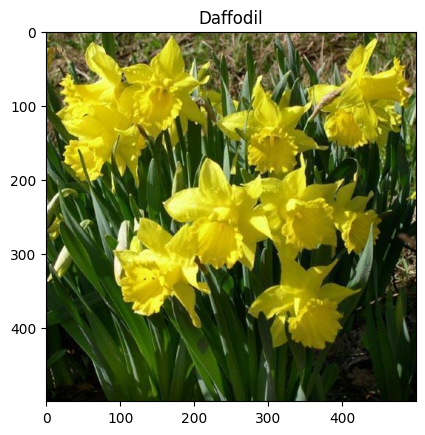

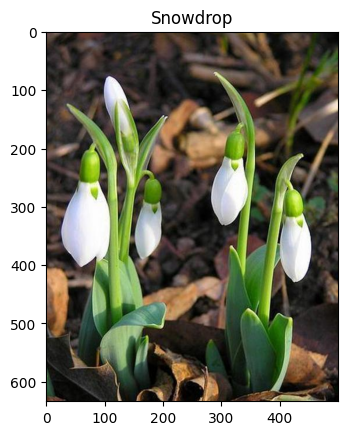

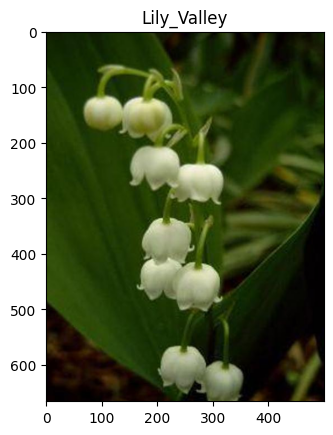

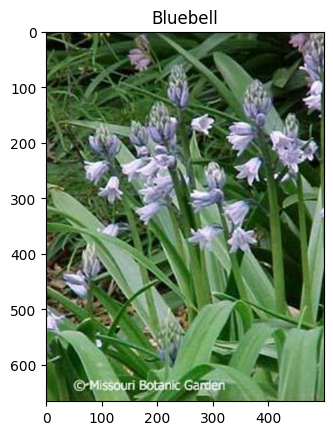

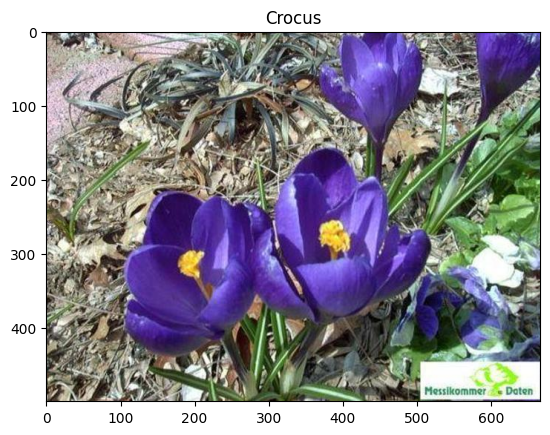

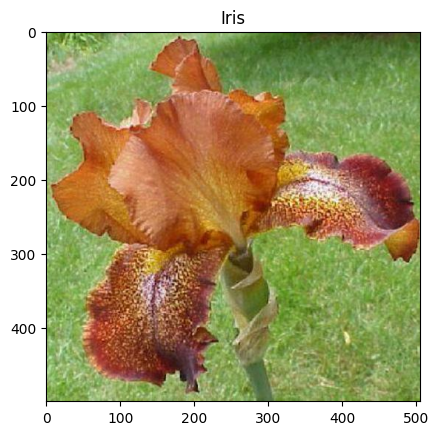

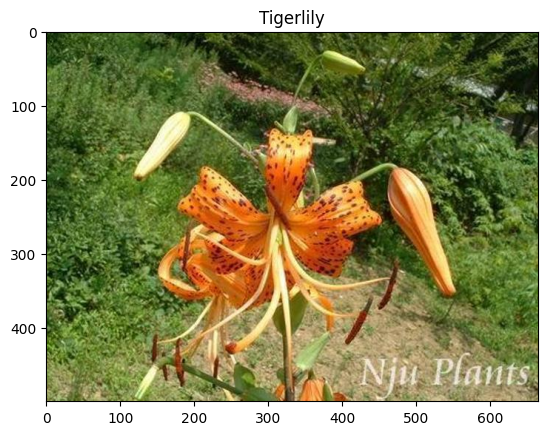

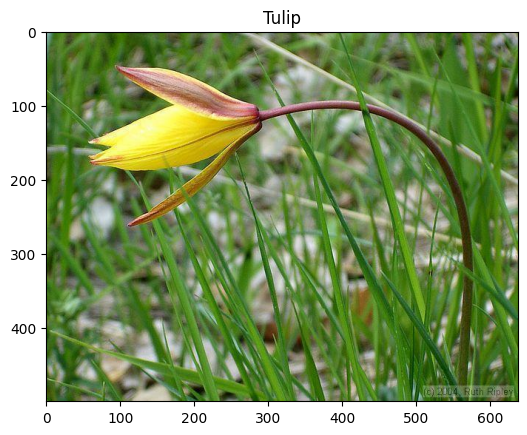

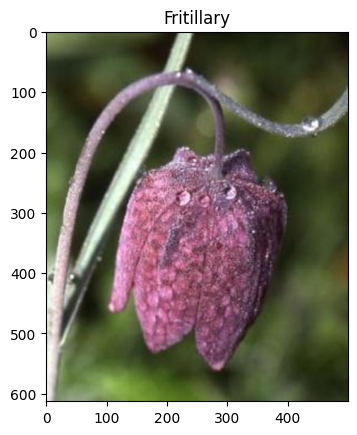

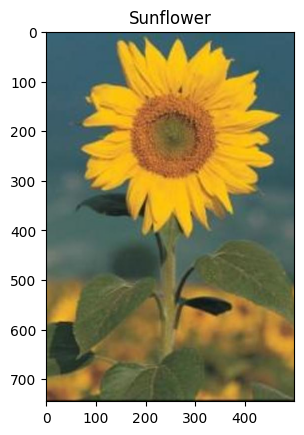

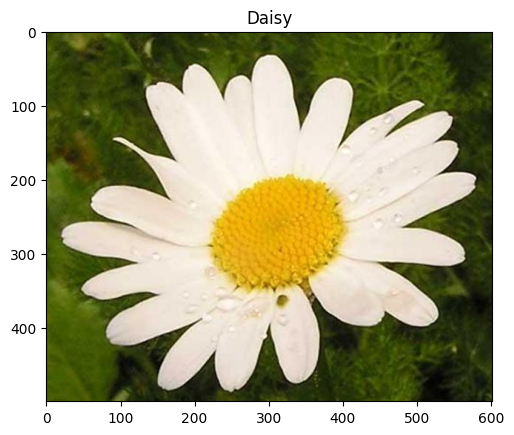

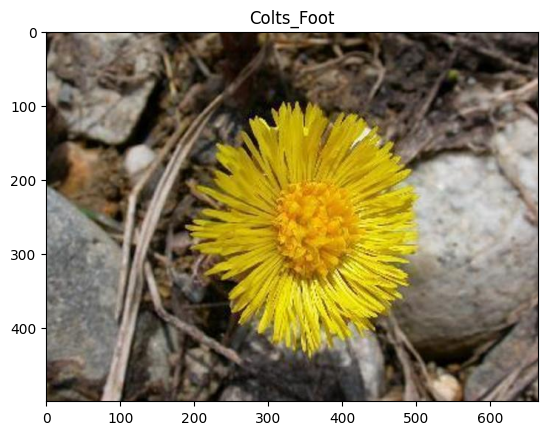

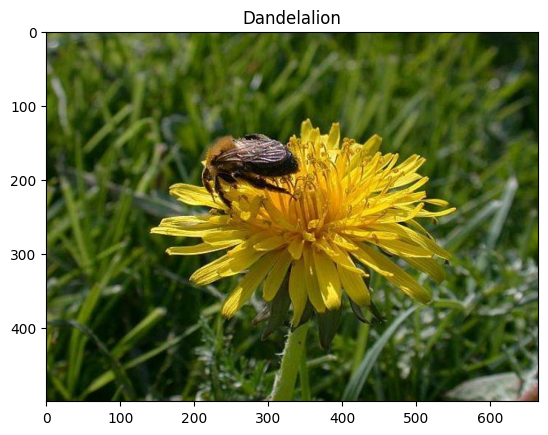

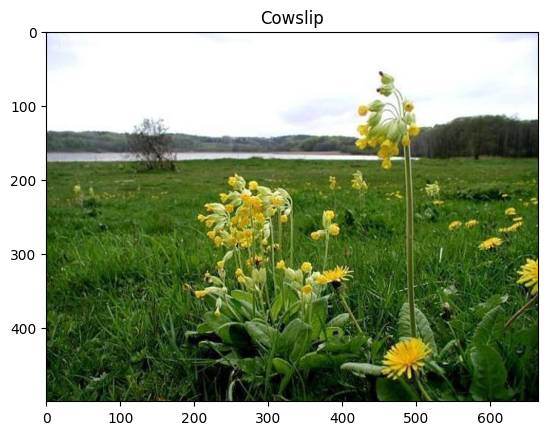

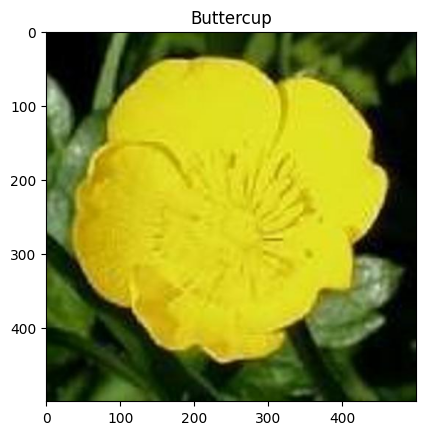

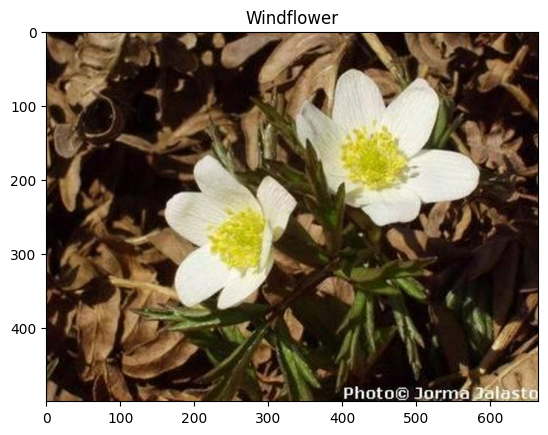

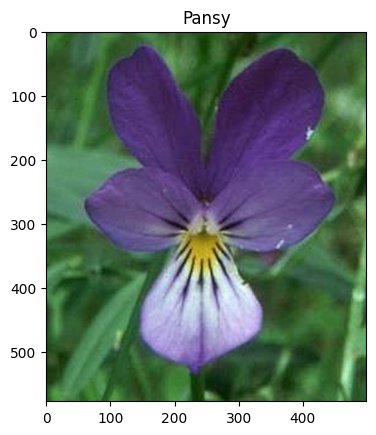

In [31]:
import imageio

for i in range(17):
  plt.imshow(imageio.imread('jpg/image_'+str(80*i+1+np.random.randint(80)).zfill(4)+'.jpg'))
  plt.title(classes[i])
  plt.show()

## Create generic dataset structure for torchvision.datasets.ImageFolder

Quoting the documentation for [```torchvision.datasets.ImageFolder```](https://pytorch.org/vision/stable/datasets.html#torchvision.datasets.ImageFolder):

> A generic data loader where the images are arranged in this way:
  ```
   root/dog/xxx.png
   root/dog/xxy.png
   root/dog/xxz.png
   ...
   root/cat/123.png
   root/cat/nsdf3.png
   root/cat/asd932_.png
   ```

In [32]:
# create folder structure for torchvision.datasets.ImageFolder
rootdir = 'flowers17'
os.makedirs(rootdir, exist_ok=True)
phases = ['train', 'test', 'val']
datadirs = [os.path.join(rootdir, x) for x in phases]
print(datadirs)
for dir in datadirs:
  os.makedirs(dir, exist_ok=True)
  for cl in classes:
    os.makedirs(os.path.join(dir,cl), exist_ok=True)

# go through the train/val/test splitting #1 of the database and copy image files:
imgnumbers = [ds['trn1'].ravel(), ds['tst1'].ravel(), ds['val1'].ravel()]
#print(imgnumbers)

for i, imgnb in enumerate(imgnumbers):
  for j in imgnb:
    fpath = 'jpg/image_'+str(j).zfill(4)+'.jpg'
    cl = (j-1)//80
    destdir = os.path.join(rootdir, phases[i], classes[cl])+'/'
    os.system('cp '+fpath+' '+destdir)

['flowers17/train', 'flowers17/test', 'flowers17/val']


## Back to PyTorch:

In [33]:
# Data augmentation and normalization for training
# Just normalization for validation
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}
data_transforms['test'] = data_transforms['val']

data_dir = rootdir
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val','test']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                             shuffle=True, num_workers=4)
              for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val','test']}
class_names = image_datasets['train'].classes
print('Class names are: ', class_names)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

Class names are:  ['Bluebell', 'Buttercup', 'Colts_Foot', 'Cowslip', 'Crocus', 'Daffodil', 'Daisy', 'Dandelalion', 'Fritillary', 'Iris', 'Lily_Valley', 'Pansy', 'Snowdrop', 'Sunflower', 'Tigerlily', 'Tulip', 'Windflower']


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


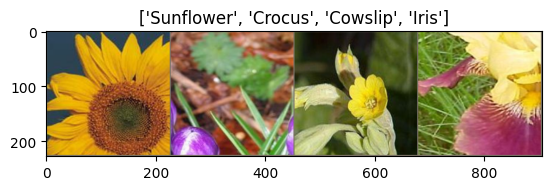

In [34]:
# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs)
imshow(out, title=[class_names[x] for x in classes])

## ResNet18 as a flower classifier

## Exercise 3:
1. Adapt the methodology of the section 'Pretrained ConvNet as fixed feature extractor' to use ResNet18 for the classification of this flower dataset.
2. Use the unseen 'test' images to evaluate the retained "best" trained model. Report the performance using metrics from scikit-learn with:



```
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
```


3. Perform fine-tuning of the full resnet18 network and compare the performances of both adapted networks.


## Pretrained ConvNet as fixed feature extractor

In [35]:
model_conv = torchvision.models.resnet18(pretrained=True)
for param in model_conv.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 17)
#il y a 17 classes de fleurs dans le dataset donc on ajuste

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that only parameters of final layer are being optimized
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [36]:
model_conv = train_model(model_conv, criterion, optimizer_conv,
                         exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------
train Loss: 2.3904 Acc: 0.2647
val Loss: 0.9848 Acc: 0.8118

Epoch 1/24
----------
train Loss: 1.4841 Acc: 0.5926
val Loss: 0.5846 Acc: 0.8706

Epoch 2/24
----------
train Loss: 1.2031 Acc: 0.6868
val Loss: 0.4201 Acc: 0.8853

Epoch 3/24
----------
train Loss: 1.0674 Acc: 0.7074
val Loss: 0.3787 Acc: 0.9088

Epoch 4/24
----------
train Loss: 0.9004 Acc: 0.7735
val Loss: 0.3232 Acc: 0.9206

Epoch 5/24
----------
train Loss: 0.8650 Acc: 0.7500
val Loss: 0.3239 Acc: 0.9029

Epoch 6/24
----------
train Loss: 0.8789 Acc: 0.7544
val Loss: 0.3411 Acc: 0.9029

Epoch 7/24
----------
train Loss: 0.7046 Acc: 0.8206
val Loss: 0.2829 Acc: 0.9353

Epoch 8/24
----------
train Loss: 0.6660 Acc: 0.8441
val Loss: 0.2682 Acc: 0.9265

Epoch 9/24
----------
train Loss: 0.6947 Acc: 0.8235
val Loss: 0.2702 Acc: 0.9353

Epoch 10/24
----------
train Loss: 0.7233 Acc: 0.8118
val Loss: 0.2664 Acc: 0.9294

Epoch 11/24
----------
train Loss: 0.7211 Acc: 0.8221
val Loss: 0.2423 Acc: 0.9382

Ep

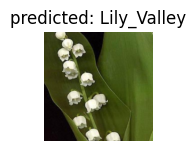

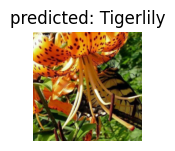

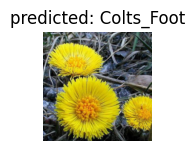

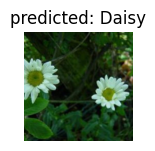

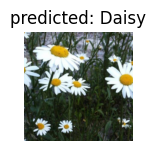

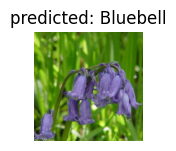

In [37]:
visualize_model(model_conv)

### Mes commentaires

Avec cette méthode, on a un temps d'excécution qui est 2min46s.
De plus, la best accuracy (0.9470) a été atteint pour l'epoch 16.

## Performance on test dataset, and evaluation using sklearn.metrics functions

In [38]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#### Création d'un dataloaders pour les données test

In [39]:
dataloaders1 = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                             shuffle=True, num_workers=4)
              for x in ['test']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val','test']}
class_names = image_datasets['train'].classes
print('Class names are: ', class_names)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

Class names are:  ['Bluebell', 'Buttercup', 'Colts_Foot', 'Cowslip', 'Crocus', 'Daffodil', 'Daisy', 'Dandelalion', 'Fritillary', 'Iris', 'Lily_Valley', 'Pansy', 'Snowdrop', 'Sunflower', 'Tigerlily', 'Tulip', 'Windflower']


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


#### Utilisation

Ici, on utilise le meilleur modele sur les données test.
Comme on utilise le modèle sur des données qu'il ne connait pas et comme on ne veut pas qu'il soit "train" sur ces données, on met en mode eval et on lui demande de ne pas calculer le gradient.

Ensuite, il faudra faire une matrice de confusion avec les vrais classes pour voir si le model est interessant.


In [47]:
model_conv.eval()
les_pred = []
les_test = []
with torch.no_grad(): #pas de calcul de gradient
    for inputs, classes in dataloaders1['test']:
      inputs = inputs.to(device)
      classes = classes.to(device)
      sortie = model_conv(inputs)
      _,pred=torch.max(sortie,1)
      #print(pred)
      t_test = classes
      #print(t_test)

      les_pred.append (pred) #pour mettre les prediction
      les_test.append (classes) #pour mettre les vrais

#pred = torch.Tensor(les_pred)
#t_test = torch.Tensor(les_test)
pred = torch.cat(les_pred).cpu()
t_test = torch.cat(les_test).cpu()

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [49]:
from sklearn.metrics import classification_report
print(classification_report(t_test, pred))



              precision    recall  f1-score   support

           0       0.95      1.00      0.98        20
           1       0.95      0.95      0.95        20
           2       0.95      0.95      0.95        20
           3       0.86      0.90      0.88        20
           4       0.95      0.95      0.95        20
           5       0.90      0.90      0.90        20
           6       1.00      1.00      1.00        20
           7       0.95      0.95      0.95        20
           8       1.00      0.90      0.95        20
           9       0.94      0.85      0.89        20
          10       0.85      0.85      0.85        20
          11       1.00      1.00      1.00        20
          12       0.89      0.80      0.84        20
          13       1.00      1.00      1.00        20
          14       0.95      1.00      0.98        20
          15       0.82      0.90      0.86        20
          16       0.95      1.00      0.98        20

    accuracy              

### Commentaire

Ici, on obtient une accuracy de 0.94 sur 340 images, ce qui est assez élevé. Notre modèle se trompe dans 6% des cas. De plus, il y a 20 images par classe.
Pour les lignes 6,11 et 13, le modèle ne s'est pas trompé une fois.
les lignes 10 et 12 ont des scores F1 les plus bas; ce qui pourrait suggérer que ces classes sont beaucoup plus difficile à apprehender pour le modèle.

Tout ceci suggère que notre méthode de feature extraction est assez efficace dans ce cas.

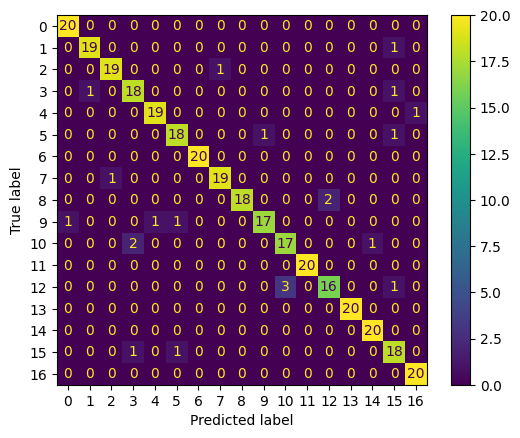

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(t_test,pred)
disp = ConfusionMatrixDisplay(cm);
disp.plot()

### commentaire

La matrice de confusion a l'air diagonale. Cependant, il y a quelques classes pour lesquelles le modèle s'est trompé.
La classe 12 est celle avec le plus d'élément gors diagonale.

## Comparison with fine-tuning of full network

### Faison du fine tunning

In [51]:
num_ftrs = model_ft.fc.in_features

# Alternatively, it can be generalized to nn.Linear(num_ftrs, len(class_names)).
model_ft.fc = nn.Linear(num_ftrs, 17)

model_ft = model_ft.to(device)
print(model_ft.fc)

criterion = nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

Linear(in_features=512, out_features=17, bias=True)


In [52]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler,
                       num_epochs=25)

Epoch 0/24
----------


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


train Loss: 2.0953 Acc: 0.3676
val Loss: 0.6094 Acc: 0.8324

Epoch 1/24
----------
train Loss: 1.0618 Acc: 0.7103
val Loss: 0.4228 Acc: 0.8912

Epoch 2/24
----------
train Loss: 0.7789 Acc: 0.7691
val Loss: 0.2904 Acc: 0.9265

Epoch 3/24
----------
train Loss: 0.5936 Acc: 0.8368
val Loss: 0.2175 Acc: 0.9412

Epoch 4/24
----------
train Loss: 0.6265 Acc: 0.8132
val Loss: 0.2870 Acc: 0.9353

Epoch 5/24
----------
train Loss: 0.5362 Acc: 0.8471
val Loss: 0.1821 Acc: 0.9559

Epoch 6/24
----------
train Loss: 0.4519 Acc: 0.8632
val Loss: 0.2020 Acc: 0.9441

Epoch 7/24
----------
train Loss: 0.3650 Acc: 0.8912
val Loss: 0.1639 Acc: 0.9647

Epoch 8/24
----------
train Loss: 0.3822 Acc: 0.9015
val Loss: 0.1817 Acc: 0.9500

Epoch 9/24
----------
train Loss: 0.3808 Acc: 0.9074
val Loss: 0.1480 Acc: 0.9559

Epoch 10/24
----------
train Loss: 0.3215 Acc: 0.9074
val Loss: 0.1423 Acc: 0.9706

Epoch 11/24
----------
train Loss: 0.3583 Acc: 0.9029
val Loss: 0.1288 Acc: 0.9735

Epoch 12/24
----------
t

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


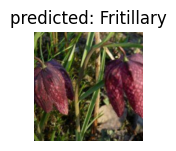

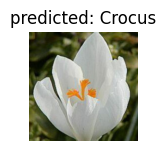

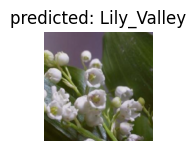

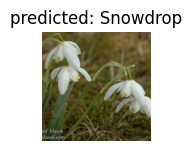

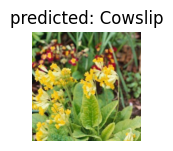

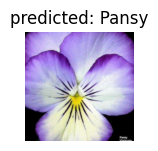

In [58]:
visualize_model(model_ft)

### Mon commentaire

Avec cette méthode, on a un temps d'excécution qui est 3min45s.
De plus, la best accuracy (0.9794) a été atteint pour l'epoch 13.

### Performance du fine tunning

In [55]:
model_ft.eval()
les_pred = []
les_test = []
with torch.no_grad(): #pas de calcul de gradient
    for inputs, classes in dataloaders1['test']:
      inputs = inputs.to(device)
      classes = classes.to(device)
      sortie = model_ft(inputs)
      _,pred=torch.max(sortie,1)
      #print(pred)
      t_test = classes
      #print(t_test)

      les_pred.append (pred) #pour mettre les prediction
      les_test.append (classes) #pour mettre les vrais

#pred = torch.Tensor(les_pred)
#t_test = torch.Tensor(les_test)
pred = torch.cat(les_pred).cpu()
t_test = torch.cat(les_test).cpu()

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [56]:
from sklearn.metrics import classification_report
print(classification_report(t_test, pred))


              precision    recall  f1-score   support

           0       0.95      0.90      0.92        20
           1       1.00      1.00      1.00        20
           2       1.00      1.00      1.00        20
           3       1.00      1.00      1.00        20
           4       0.95      0.90      0.92        20
           5       0.90      0.90      0.90        20
           6       1.00      1.00      1.00        20
           7       1.00      1.00      1.00        20
           8       1.00      0.95      0.97        20
           9       0.95      0.90      0.92        20
          10       0.95      0.95      0.95        20
          11       1.00      1.00      1.00        20
          12       0.91      1.00      0.95        20
          13       1.00      1.00      1.00        20
          14       1.00      1.00      1.00        20
          15       0.90      0.95      0.93        20
          16       0.95      1.00      0.98        20

    accuracy              

### Commentaire

Avec cette méthode, on a une accuracy de 0.97 avec un support de 340 images. Ce qui très satisfaisant.
Sur les 17 classes, le modèle a fait un sans faute sur près de la moitié des classes. En effet, les classes 1,2,3,6,7,11,13 et 14  sont celles qui ont obtenu les meilleurs scores.
Les classes 0 et 4 ont les scores les plus bas, ce qui signifient que ces classes sont assez compliqué à distinguer pour notre modèle.
La classe 12 est celle qui a la précision la plus petite mais son recall est 1; cela suggère que le modèle est bon pour trouver les images de la classe 12 mais, quand il attribut la classe 12, il a raison à 91% .


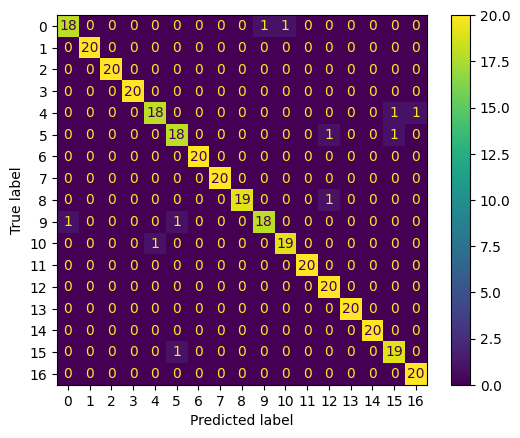

In [57]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(t_test,pred)
disp = ConfusionMatrixDisplay(cm);
disp.plot()

### Commentaire

Cette matrice également a l'air diagonale. Mais, il y a des classes où, des éléments sont en dehors de la diagonale.

### Comparaison des 2 approches

La méthode de fine tuning, bien qu'elle prends beaucoup plus de temps a de meilleurs résultats sur les données de test que la méthode du feature extraction.